In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

In [2]:
# Conjunto já disponível na biblioteca sklearn
mnist = fetch_openml('mnist_784', version=1) 

In [ ]:
# Formato retornado, semelhante ao dict: possui chaves e valores
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [4]:
# Armazenando apenas as colunas a serem utilizadas
x, y = mnist['data'].values, mnist['target'].values
y = y.astype(np.float64)

In [5]:
# x representa cada pixel das imagens do conjunto
x

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784))

In [6]:
# y representa o número ao qual os pixels de x corresponde
y

array([5., 0., 4., ..., 4., 5., 6.], shape=(70000,))

1.0


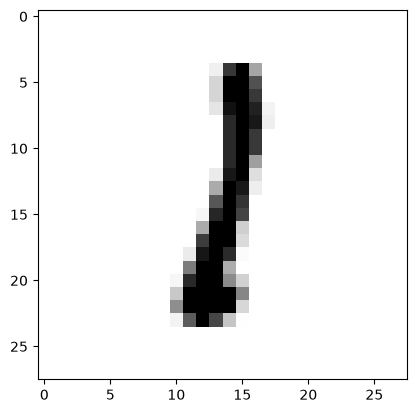

In [ ]:
# Verificando graficamente qual valor corresponde a posição n  
n = 152

plt.imshow(x[n].reshape(28, 28), cmap='binary')
print(y[n])
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

In [ ]:
# Treinamento do SGD
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier()
sgd_clf.fit(x_train, y_train)

,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if th

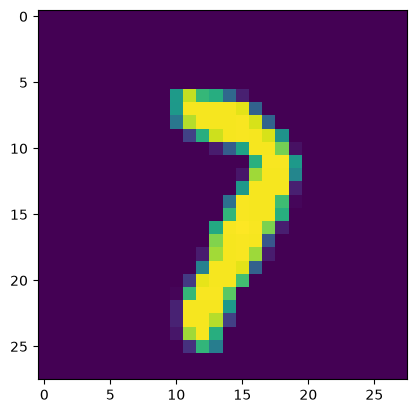

In [10]:
n = 30

digit = x_train[n]
plt.imshow(digit.reshape(28,28))

In [ ]:
# Fazendo uma verificação do valor previsto na posição digit
sgd_clf.predict([digit])

array([7.])

In [ ]:
# Cross validation predict para verificar generalização do modelo
from sklearn.model_selection import cross_val_predict

y_train_pred = cross_val_predict(sgd_clf, x_train, y_train, cv=3)

In [ ]:
# Array com as previsões feitas
y_train_pred

array([5., 0., 4., ..., 8., 1., 9.], shape=(49000,))

In [14]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [ ]:
# Matriz de confusão e métricas de FP, TP, FN e TN
conf_mx = confusion_matrix(y_train, y_train_pred)
print(conf_mx)
print(classification_report(y_train, y_train_pred))

[[4667    1   19   11    7    2   27    1   59   10]
 [   1 5275   50   16    7   11    8   10  164   26]
 [  41   49 4198   80   47   14   74   50  296   27]
 [  43   17  171 4258   13   89   23   36  254   78]
 [  20   15   54   12 3840    3   42   37  294  451]
 [ 117   21   83  240   48 3261  106   22  443  102]
 [  44   18  157    8   23   77 4370    4   79    0]
 [  36   16   88   46   49    4    2 4253   87  547]
 [  46   45  134  127   25   60   40   22 4210   99]
 [  33   16   29   51  139   19    4  166  181 4205]]
              precision    recall  f1-score   support

         0.0       0.92      0.97      0.95      4804
         1.0       0.96      0.95      0.96      5568
         2.0       0.84      0.86      0.85      4876
         3.0       0.88      0.85      0.87      4982
         4.0       0.91      0.81      0.86      4768
         5.0       0.92      0.73      0.82      4443
         6.0       0.93      0.91      0.92      4780
         7.0       0.92      0.83   

<Axes: >

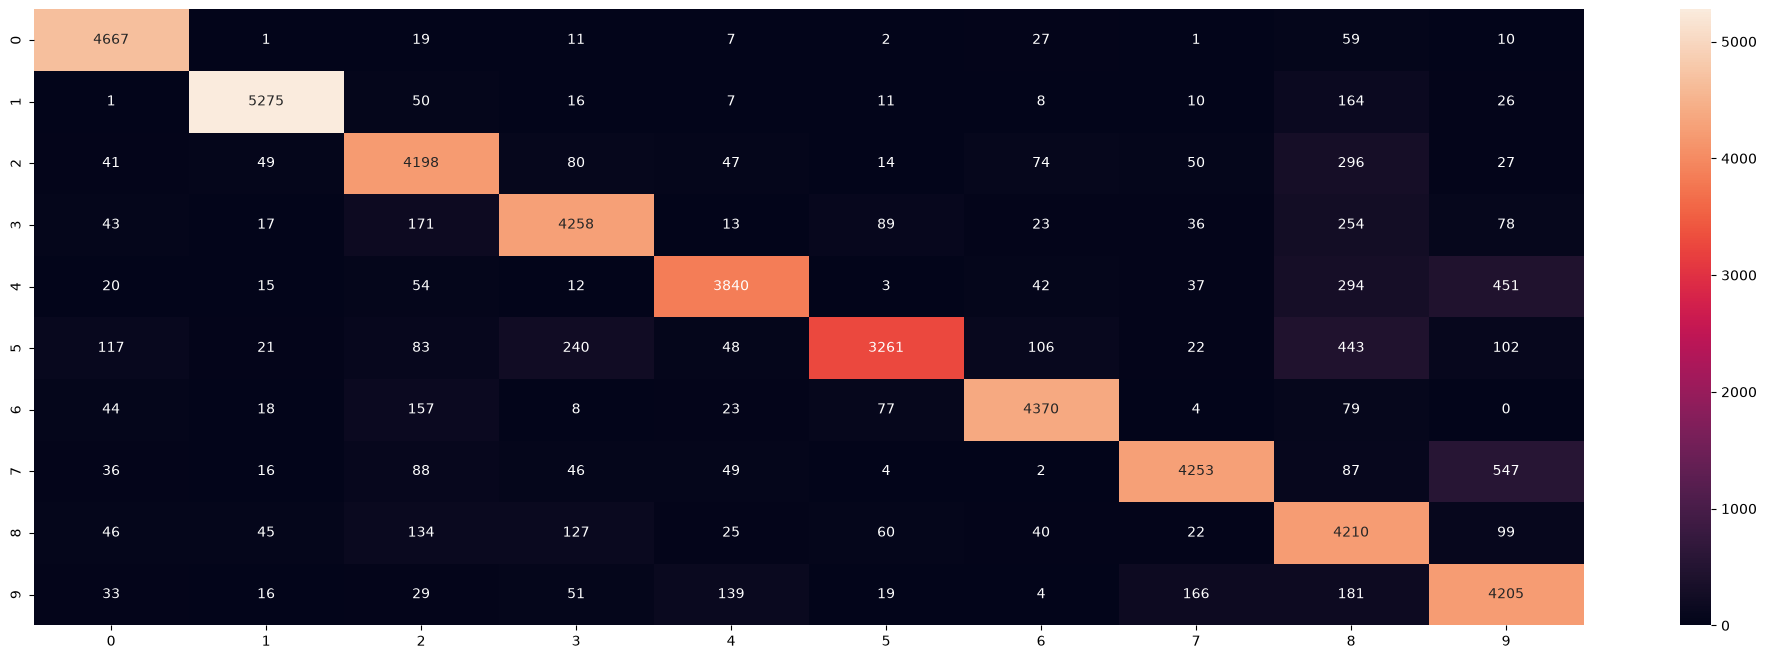

In [ ]:
#Matriz de confusão plotada
fig, ax = plt.subplots(figsize=(25,8))
sns.heatmap(conf_mx, annot=True, fmt='.0f')

In [17]:
row_sums = conf_mx.sum(axis=1, keepdims=True)
norm_conf_mx = conf_mx / row_sums

np.fill_diagonal(norm_conf_mx, 0)

<Axes: >

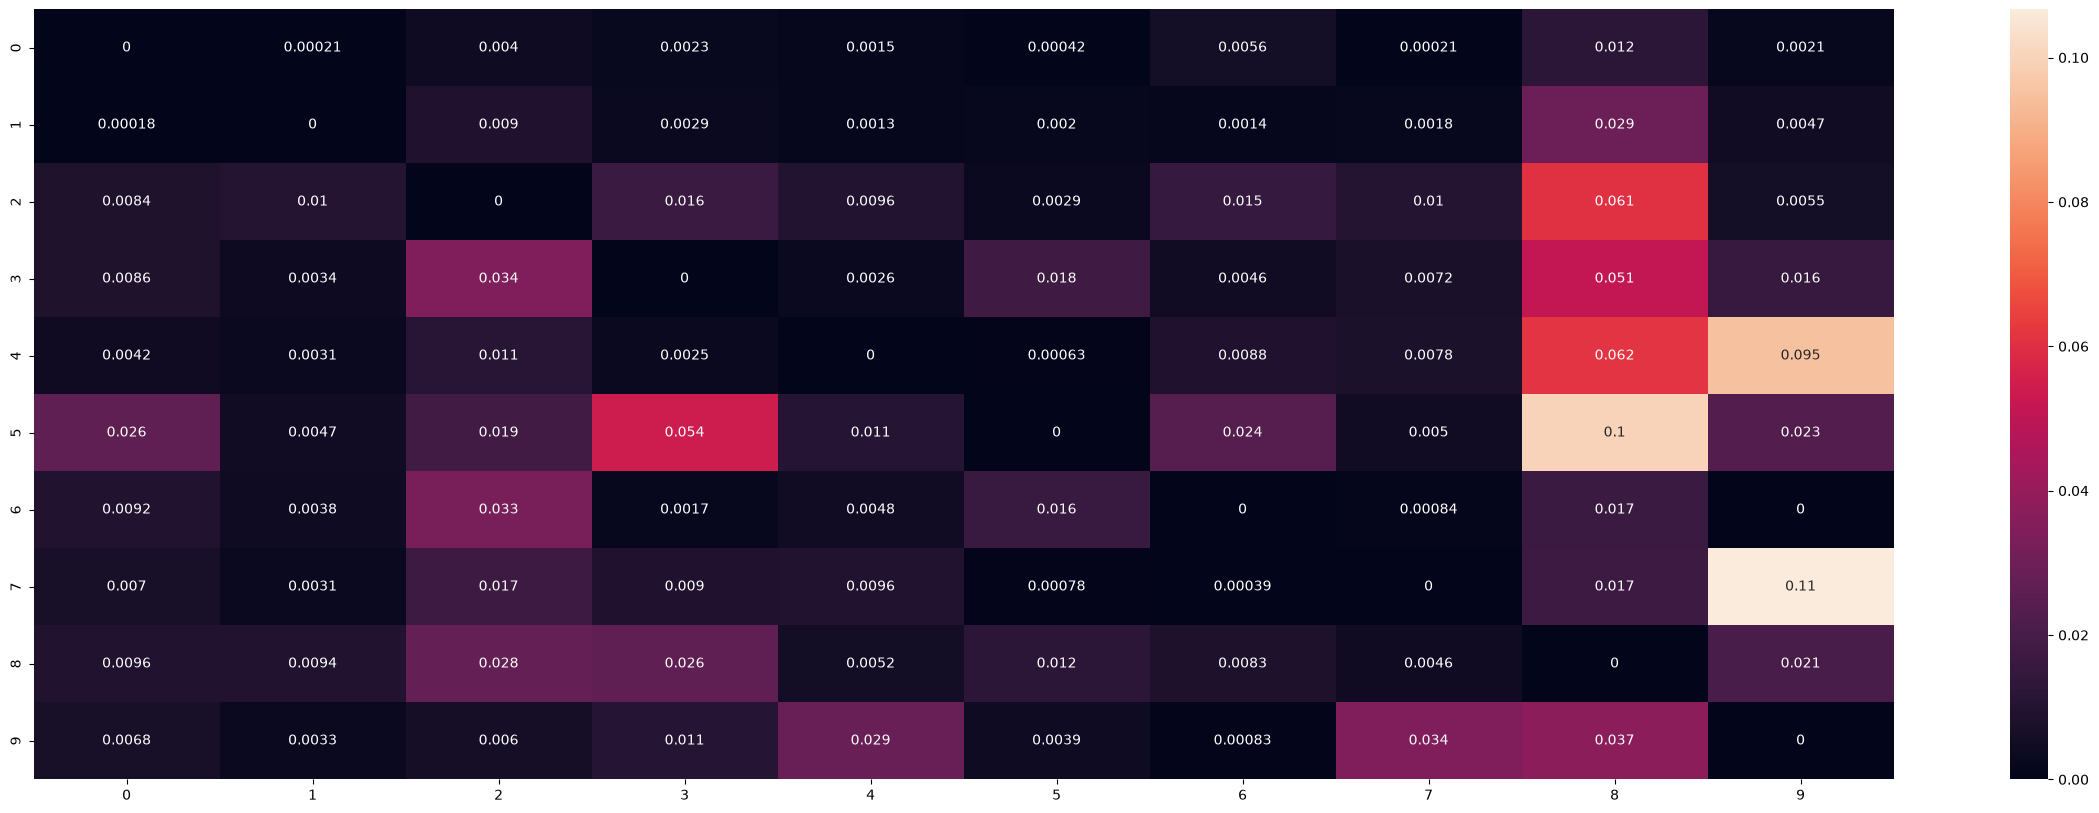

In [ ]:
# Calculando os valores absolutos em proporções de erros e acertos por classe
fig, ax = plt.subplots(figsize=(30,10))
sns.heatmap(norm_conf_mx, ax=ax, annot=True)